In [ ]:
# %pip install torch torchvision

In [1]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Part 1 : encoder
# which maps input to latent space

class Encoder(nn.Module):
  def __init__(self, input_dim, hidden_dim, latent_dim):
    """
    Initialize the encoder class
    Args:
    input_dim: dimention of input data
    hidden_dim: dimention of hidden layer
    latent_dim: dimention of latent space
    """

    super(Encoder, self).__init__()
    # define the fully connected layer
    self.fc1=nn.Linear(input_dim, hidden_dim)
    self.fc_mu=nn.Linear(hidden_dim, latent_dim)
    self.fc_logvar=nn.Linear(hidden_dim, latent_dim)

  # define forward propagation step
  def forward(self, x):
    """
    Define forward pass through encoder
    Args:
    x: input data

    output:
    mu: mean of the latent space
    logvar: the log variation of latent space
    """

    # apply ReLU activation to hidden layer
    h=torch.relu(self.fc1(x))

    mu= self.fc_mu(h)
    logvar=self.fc_logvar(h)
    return mu, logvar

In [3]:
# define decoder class, which maps latent space to output
class Decoder(nn.Module):
  def __init__(self, latent_dim, hidden_dim, output_dim):
    """
    Initialize th decoder class
    Args:
    latent_dim: dimention of latent space
    hidden_dim: dimention of hidden layer
    output_dim: dimention of output data
    """

    super(Decoder, self).__init__()
    # define fully connected layer for decoder
    self.fc1=nn.Linear(latent_dim, hidden_dim)
    self.fc2=nn.Linear(hidden_dim, output_dim)

  # define the forward pass through decoder
  def forward(self, z):
    """
    Define forward pass through decoder
    Args:
    z: latent space data

    output:
    x_hat: reconstructed data
    """

    # apply relu to hidden layer
    h=torch.relu(self.fc1(z))

    # range of 0-9
    # apply sigmoid to the output layer, our output will be range of 0-9
    x_hat=torch.sigmoid(self.fc2(h))

    return x_hat


In [5]:
# define VAE class
class VAE(nn.Module):
  def __init__(self, input_dim, hidden_dim, latent_dim):
    """
    Initialize th VAE class
    Args:
    input_dim: dimention of input data
    hidden_dim: dimention of hidden layer
    latent_dim: dimention of latent space
    """

    super(VAE,self).__init__()

    # define encoder and decoder instances
    self.encoder=Encoder(input_dim=input_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
    self.decoder=Decoder(latent_dim=latent_dim, hidden_dim=hidden_dim, output_dim=input_dim)

  def forward(self, x):
    """
    Define forward pass through VAE
    Args:
    x: input data

    output:
    x_hat: the reconstructed data
    mu: mean of the latent space
    logvar: the log variation oof latent space
    """

    # encoder the input to the latent space
    mu, logvar=self.encoder(x)

    # sample from latent space using reparametrization trick
    std=torch.exp(0.5 * logvar)
    eps=torch.randn_like(std)
    z=mu+ eps*std
    x_hat=self.decoder(z)
    return x_hat, mu, logvar

In [6]:
# define loss function

def loss_function(x, x_hat, mu, logvar):
    '''
    Args:
    x: input data
    x_hat: the reconstructed output data
    mu: mean of the latent space
    logvar: log varience of latent space

    Returns:
    loss: VAE loss
    '''
    # calculate binary cross entropy
    BCE= nn.functional.binary_cross_entropy(x_hat, x, reduction='sum')

    # calculate KL = Kullback-leibler divergence loss
    KLD= -0.5 * torch.sum(1+logvar - mu.pow(2) -logvar.exp())

    return BCE + KLD

In [7]:
input_dim= 784
hidden_dim=400
latent_dim= 20

lr=1e-3
batch_size=128
epochs=10

# dataloader
transform= transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x.view(-1))])
train_dataset=datasets.MNIST(root='./data', train=True, download= True, transform=transform)
data_loader=DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 461kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.3MB/s]


In [8]:
# model , optimizer
vae= VAE(input_dim=input_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)

optimizer= optim.Adam(vae.parameters(), lr=lr)

# train loop
for epoch in range(epochs):
    train_loss= 0
    for x, _ in data_loader:
        # convert image to 784 length array
        x=x.view(-1, input_dim)

        # resetting optimizer
        optimizer.zero_grad()

        x_hat, mu, logvar=vae(x)

        loss= loss_function(x, x_hat, mu, logvar)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    print(f'Epoch: {epoch+1}, Loss: {train_loss/len(data_loader.dataset)}')

Epoch: 1, Loss: 166.16474625651043
Epoch: 2, Loss: 122.03768611653646
Epoch: 3, Loss: 114.59585799153646
Epoch: 4, Loss: 111.58447913411459
Epoch: 5, Loss: 109.84349868164063
Epoch: 6, Loss: 108.62348862304688
Epoch: 7, Loss: 107.80814666341146
Epoch: 8, Loss: 107.10536217447917
Epoch: 9, Loss: 106.6112755859375
Epoch: 10, Loss: 106.1840248860677


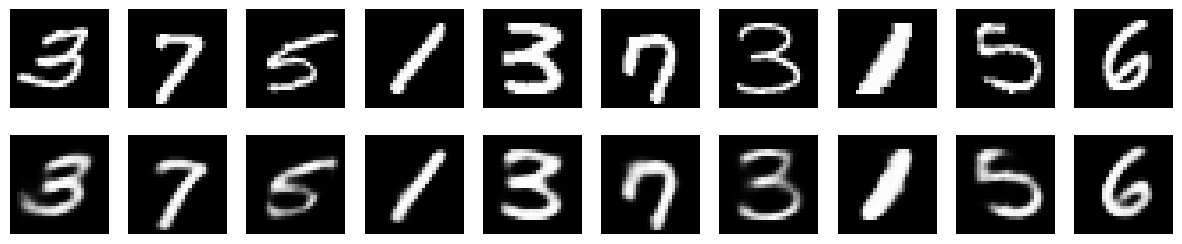

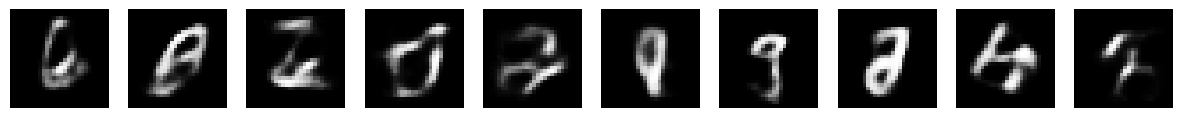

In [15]:
# Testing and evaluation
vae.eval()

# reconstruction of the input data
with torch.no_grad():
    x, _= next(iter(data_loader))
    x= x.view(-1, input_dim)
    x_hat, _, _= vae(x)
    x=x.view(-1, 28, 28)
    x_hat=x_hat.view(-1, 28, 28)

    fig, axs=plt.subplots(2, 10, figsize=(15, 3))

    for i in range(10):
        axs[0, i].imshow(x[i].cpu().numpy(), cmap='gray')
        axs[1, i].imshow(x_hat[i].cpu().numpy(), cmap='gray')
        axs[0, i].axis('off')
        axs[1, i].axis('off')
    plt.show()
    # visualizing newly generated data
with torch.no_grad():
    z=torch.randn(10, latent_dim)
    sample=vae.decoder(z)
    sample=sample.view(-1, 28, 28)

    fig, axs=plt.subplots(1, 10, figsize=(15, 3))

    for i in range(10):
        axs[i].imshow(sample[i].cpu().numpy(), cmap='gray')
        axs[i].axis('off')
    plt.show()

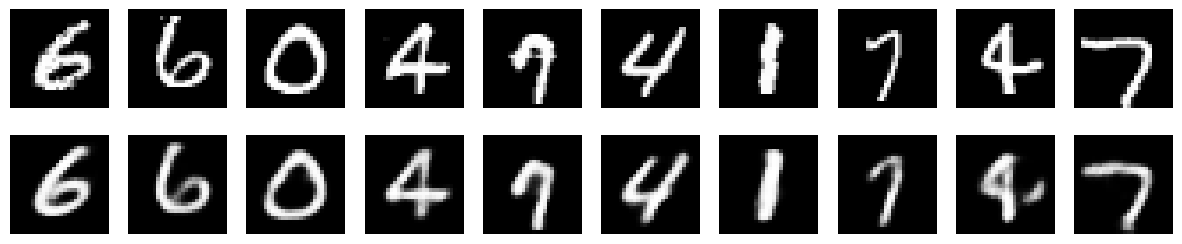

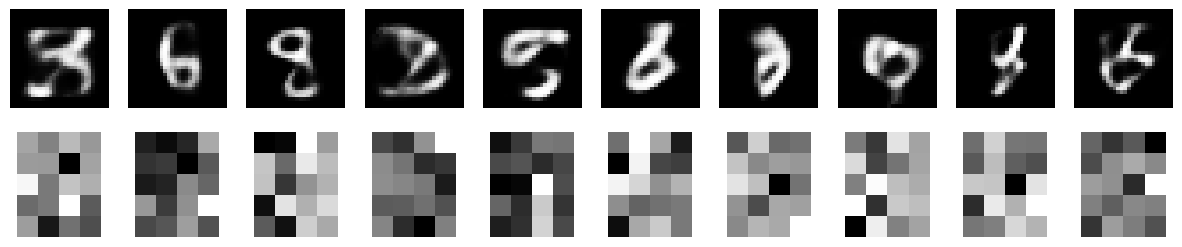

In [23]:
# Testing and evaluation
vae.eval()

# reconstruction of the input data
with torch.no_grad():
    x, _= next(iter(data_loader))
    x= x.view(-1, input_dim)
    x_hat, _, _= vae(x)
    x=x.view(-1, 28, 28)
    x_hat=x_hat.view(-1, 28, 28)

    fig, axs=plt.subplots(2, 10, figsize=(15, 3))

    for i in range(10):
        axs[0, i].imshow(x[i].cpu().numpy(), cmap='gray')
        axs[1, i].imshow(x_hat[i].cpu().numpy(), cmap='gray')
        axs[0, i].axis('off')
        axs[1, i].axis('off')
    plt.show()
    # visualizing newly generated data
with torch.no_grad():
    z=torch.randn(10, latent_dim)
    sample=vae.decoder(z)
    sample=sample.view(-1, 28, 28)
    z=z.view(-1, 5, 4)
    fig, axs=plt.subplots(2, 10, figsize=(15, 3))

    for i in range(10):
        axs[0, i].imshow(sample[i].cpu().numpy(), cmap='gray')
        axs[0, i].axis('off')
        axs[1, i].imshow(z[i].cpu().numpy(), cmap='gray')
        axs[1, i].axis('off')
    plt.show()

In [19]:
torch.randn(10, latent_dim).shape

torch.Size([10, 20])